# Synthèse du papier U-Net : notebook

Article : *U-Net: Convolutional Networks for Biomedical Image Segmentation*



In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
print("numpy", np.__version__)

numpy 2.5.3


## 1. Tailles des cartes (overlap-tile)



In [2]:
def unet_sizes(n_in=572, depth=4):
    """Taille (côté du carré) après chaque étape du U-Net."""
    rows, skips, s = [], [], n_in
    for lvl in range(1, depth + 1):              # chemin contractant
        s -= 2; rows.append((f"contract {lvl} conv 3x3", s))
        s -= 2; rows.append((f"contract {lvl} conv 3x3", s))
        skips.append(s)                           # carte gardée pour la copie
        assert s % 2 == 0, "taille impaire : max-pool 2x2 impossible"
        s //= 2; rows.append((f"contract {lvl} max-pool 2x2", s))
    s -= 2; rows.append(("goulot conv 3x3", s))
    s -= 2; rows.append(("goulot conv 3x3", s))
    for lvl in reversed(range(depth)):           # chemin expansif
        s *= 2; rows.append((f"expand {lvl+1} up-conv 2x2", s))
        assert skips[lvl] >= s, "la copie doit être plus grande pour être rognée"
        s -= 2; rows.append((f"expand {lvl+1} conv 3x3", s))
        s -= 2; rows.append((f"expand {lvl+1} conv 3x3", s))
    rows.append(("sortie conv 1x1", s))
    return rows, s

rows, final = unet_sizes(572)
for name, size in rows:
    print(f"{name:<26} {size} x {size}")

print()
print(f"Taille finale : {final} x {final}  (article : 388 x 388)")
print(f"Marge perdue de chaque côté : {(572 - final) // 2} px")

n_conv3 = sum(1 for n, _ in rows if "conv 3x3" in n)
n_up = sum(1 for n, _ in rows if "up-conv" in n)
n_1x1 = sum(1 for n, _ in rows if "1x1" in n)
print(f"\nConv 3x3 : {n_conv3}, up-conv : {n_up}, conv 1x1 : {n_1x1}")
print(f"Total (up-conv et 1x1 comptés) : {n_conv3 + n_up + n_1x1}  (article : 23 couches)")
assert final == 388

contract 1 conv 3x3        570 x 570
contract 1 conv 3x3        568 x 568
contract 1 max-pool 2x2    284 x 284
contract 2 conv 3x3        282 x 282
contract 2 conv 3x3        280 x 280
contract 2 max-pool 2x2    140 x 140
contract 3 conv 3x3        138 x 138
contract 3 conv 3x3        136 x 136
contract 3 max-pool 2x2    68 x 68
contract 4 conv 3x3        66 x 66
contract 4 conv 3x3        64 x 64
contract 4 max-pool 2x2    32 x 32
goulot conv 3x3            30 x 30
goulot conv 3x3            28 x 28
expand 4 up-conv 2x2       56 x 56
expand 4 conv 3x3          54 x 54
expand 4 conv 3x3          52 x 52
expand 3 up-conv 2x2       104 x 104
expand 3 conv 3x3          102 x 102
expand 3 conv 3x3          100 x 100
expand 2 up-conv 2x2       200 x 200
expand 2 conv 3x3          198 x 198
expand 2 conv 3x3          196 x 196
expand 1 up-conv 2x2       392 x 392
expand 1 conv 3x3          390 x 390
expand 1 conv 3x3          388 x 388
sortie conv 1x1            388 x 388

Taille finale : 38

## 2. Initialisation He



In [3]:
N = 3 * 3 * 64
std_he = np.sqrt(2 / N)
print(f"N = {N} ; écart-type He = sqrt(2/N) = {std_he:.4f}")

def propager(std_fn, profondeur=10, n=N, n_echantillons=2000):
    x = np.random.randn(n_echantillons, n)       # entrée de variance 1
    rms = []
    for _ in range(profondeur):
        W = np.random.randn(n, n) * std_fn(n)
        x = np.maximum(0, x @ W)                  # ReLU
        rms.append(np.sqrt(np.mean(x ** 2)))
    return rms

rms_he = propager(lambda n: np.sqrt(2 / n))
rms_petit = propager(lambda n: 0.01)
print()
print("couche | RMS (He)  | RMS (écart-type 0.01)")
for i, (a, b) in enumerate(zip(rms_he, rms_petit), 1):
    print(f"{i:>6} | {a:9.4f} | {b:.2e}")

N = 576 ; écart-type He = sqrt(2/N) = 0.0589

couche | RMS (He)  | RMS (écart-type 0.01)
     1 |    1.0002 | 1.70e-01
     2 |    0.9628 | 2.89e-02
     3 |    1.0042 | 5.20e-03
     4 |    1.0248 | 9.07e-04
     5 |    0.9768 | 1.58e-04
     6 |    0.9506 | 2.72e-05
     7 |    0.9139 | 4.50e-06
     8 |    0.9606 | 7.74e-07
     9 |    0.9240 | 1.37e-07
    10 |    0.9196 | 2.29e-08


## 3. Poids de pixels (équation 2)



poids max : 10.8
poids moyen sur la frontière entre cellules : 10.78
poids moyen à l'intérieur, loin des frontières : 1.27


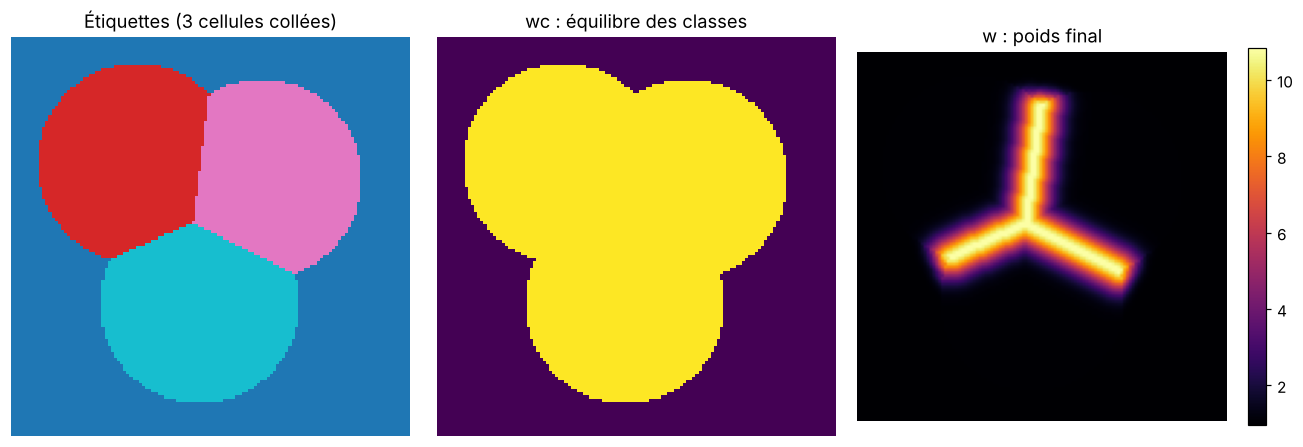

In [4]:
H = W_ = 128
yy, xx = np.mgrid[0:H, 0:W_]
centres = [(40, 40), (45, 80), (85, 60)]      # trois cellules collées
dist_centres = np.stack([np.hypot(yy - cy, xx - cx) for cy, cx in centres])
nearest = dist_centres.argmin(axis=0) + 1
mask = dist_centres.min(axis=0) < 32            # zone des cellules
labels = np.where(mask, nearest, 0)             # 0 = fond, 1..3 = cellules

cellules = [labels == k for k in range(1, 4)]
dists = np.stack([ndimage.distance_transform_edt(~c) for c in cellules])
dists.sort(axis=0)
d1, d2 = dists[0], dists[1]
w0, sigma = 10.0, 5.0
w_border = w0 * np.exp(-((d1 + d2) ** 2) / (2 * sigma ** 2))

# poids de classe : équilibre fond / cellules
n_tot = labels.size
wc = np.where(mask, n_tot / (2 * mask.sum()), n_tot / (2 * (~mask).sum()))
w = wc + w_border

print(f"poids max : {w.max():.1f}")
print(f"poids moyen sur la frontière entre cellules : {w[(d1 + d2) <= 1.5].mean():.2f}")
print(f"poids moyen à l'intérieur, loin des frontières : {w[(d1 == 0) & (d2 > 8)].mean():.2f}")

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(labels, cmap="tab10"); ax[0].set_title("Étiquettes (3 cellules collées)")
ax[1].imshow(wc, cmap="viridis"); ax[1].set_title("wc : équilibre des classes")
im = ax[2].imshow(w, cmap="inferno"); ax[2].set_title("w : poids final")
for a in ax: a.axis("off")
fig.colorbar(im, ax=ax[2], fraction=0.046)
plt.tight_layout()

## 4. Perte : softmax par pixel et entropie croisée pondérée (équation 1)

Pour chaque pixel : softmax sur les canaux, puis entropie croisée multipliée par le poids w.



In [5]:
def softmax_pixel(a):
    """a : (K, H, W) -> probabilités par pixel (somme sur les canaux = 1)."""
    a = a - a.max(axis=0, keepdims=True)          # stabilité numérique
    e = np.exp(a)
    return e / e.sum(axis=0, keepdims=True)

def cross_entropy_ponderee(p, etiquettes, poids):
    p_vraie = np.take_along_axis(p, etiquettes[None], axis=0)[0]
    return -(poids * np.log(p_vraie + 1e-12)).sum()

etiq = mask.astype(int)                           # 1 = cellule, 0 = fond
K = 2

parfait = 20.0 * np.stack([1 - etiq, etiq]).astype(float)
aleatoire = np.random.randn(K, H, W_)

print("somme des probabilités = 1 :", np.allclose(softmax_pixel(aleatoire).sum(axis=0), 1))
print(f"Perte, sorties parfaites   : {cross_entropy_ponderee(softmax_pixel(parfait), etiq, w):.4f}")
print(f"Perte, sorties aléatoires : {cross_entropy_ponderee(softmax_pixel(aleatoire), etiq, w):.1f}")

print()
print("Effet de l'échelle des logits sur p_max (deux classes, logits 2.0 et 0.5) :")
for s in [1, 5, 20]:
    p = softmax_pixel(s * np.array([2.0, 0.5]).reshape(2, 1, 1))
    print(f"  logits x{s:<3} -> p_max = {p.max():.4f}")

somme des probabilités = 1 : True
Perte, sorties parfaites   : 0.0001
Perte, sorties aléatoires : 26583.0

Effet de l'échelle des logits sur p_max (deux classes, logits 2.0 et 0.5) :
  logits x1   -> p_max = 0.8176
  logits x5   -> p_max = 0.9994
  logits x20  -> p_max = 1.0000


## 5. Augmentation par déformations élastiques



déformation 1 : étiquettes présentes = [0 1 2 3]
déformation 2 : étiquettes présentes = [0 1 2 3]


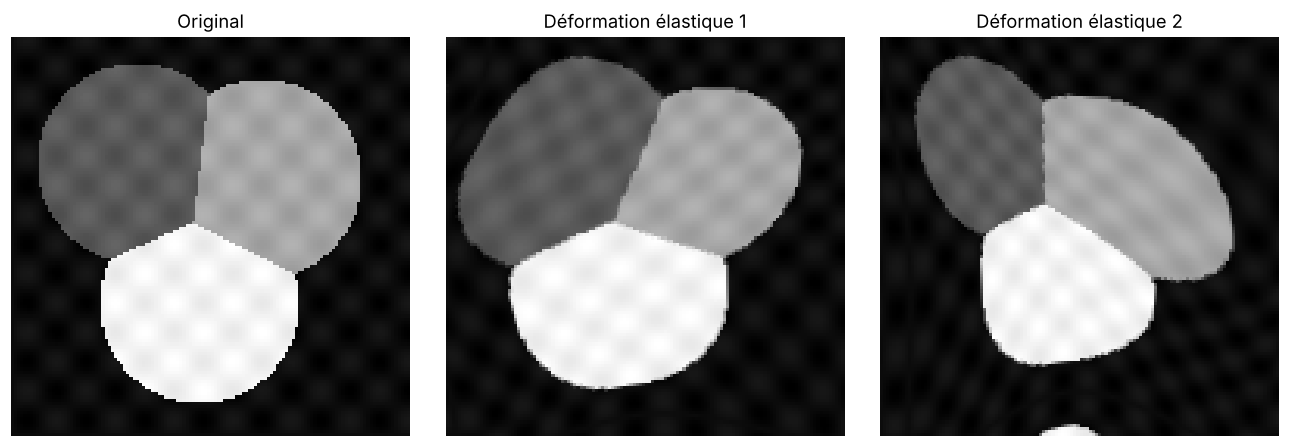

In [6]:
def champ_elastique(forme, grille=3, sigma=10.0):
    """Déplacements aléatoires sur une grille 3x3, interpolés bicubiquement."""
    h, w_ = forme
    dy = ndimage.zoom(np.random.normal(0, sigma, (grille, grille)), (h / grille, w_ / grille), order=3)
    dx = ndimage.zoom(np.random.normal(0, sigma, (grille, grille)), (h / grille, w_ / grille), order=3)
    gy, gx = np.mgrid[0:h, 0:w_]
    return gy + dy, gx + dx

def appliquer(image, coords, ordre):
    return ndimage.map_coordinates(image, coords, order=ordre, mode="mirror")

image = labels.astype(float) + 0.15 * np.sin(xx / 3.0) * np.cos(yy / 3.0)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(image, cmap="gray"); ax[0].set_title("Original")
for k in [1, 2]:
    coords = champ_elastique((H, W_))
    img_def = appliquer(image, coords, 1)          # image : interpolation linéaire
    lab_def = appliquer(labels, coords, 0)         # masque : ordre 0 (pas de valeurs mélangées)
    ax[k].imshow(img_def, cmap="gray")
    ax[k].set_title(f"Déformation élastique {k}")
    print(f"déformation {k} : étiquettes présentes = {np.unique(lab_def)}")
for a in ax: a.axis("off")
plt.tight_layout()

## 6. Résultats publiés

Valeurs copiées de l'article (tableaux 1 et 2). Pour le tableau 1, une valeur plus basse est mieux . Pour le tableau 2 , une valeur plus haute est mieux aussi 

Tableau 1 : EM (valeurs plus basses = meilleures)
  u-net      warping error=0.000353  Rand error=0.0382  pixel error=0.0611
  IDSIA [1]  warping error=0.00042  Rand error=0.0504  pixel error=0.0613
  DIVE       warping error=0.00043  Rand error=0.0545  pixel error=0.0582
  DIVE-SCI   warping error=0.000355  Rand error=0.0305  pixel error=0.0584

Meilleur warping error : u-net
Meilleur Rand error : DIVE-SCI
Meilleur pixel error : DIVE

u-net vs IDSIA sur warping error : +16.0 %
u-net vs IDSIA sur Rand error : +24.2 %
u-net vs IDSIA sur pixel error : +0.3 %

Tableau 2 : ISBI cell tracking 2015 (IOU)
  PhC-U373 : u-net 0.9203 vs second 0.83  -> +9.0 points
  DIC-HeLa : u-net 0.7756 vs second 0.46  -> +31.6 points


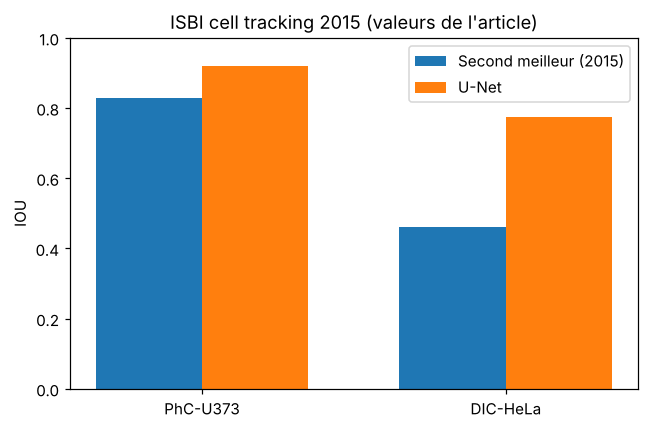

In [7]:
tab1 = {  # EM segmentation challenge (ISBI 2012), tableau 1
    "u-net":     (0.000353, 0.0382, 0.0611),
    "IDSIA [1]": (0.000420, 0.0504, 0.0613),
    "DIVE":      (0.000430, 0.0545, 0.0582),
    "DIVE-SCI":  (0.000355, 0.0305, 0.0584),
}
metriques = ["warping error", "Rand error", "pixel error"]

print("Tableau 1 : EM (valeurs plus basses = meilleures)")
for nom, vals in tab1.items():
    print(f"  {nom:<10} " + "  ".join(f"{m}={v}" for m, v in zip(metriques, vals)))

print()
for i, m in enumerate(metriques):
    best = min(tab1, key=lambda k: tab1[k][i])
    print(f"Meilleur {m} : {best}")

ref, un = tab1["IDSIA [1]"], tab1["u-net"]
print()
for i, m in enumerate(metriques):
    gain = (ref[i] - un[i]) / ref[i] * 100
    print(f"u-net vs IDSIA sur {m} : {gain:+.1f} %")

iou = {
    "PhC-U373": {"second-best 2015": 0.83, "u-net": 0.9203},
    "DIC-HeLa": {"second-best 2015": 0.46, "u-net": 0.7756},
}
print()
print("Tableau 2 : ISBI cell tracking 2015 (IOU)")
for d, v in iou.items():
    print(f"  {d} : u-net {v['u-net']:.4f} vs second {v['second-best 2015']:.2f}  -> +{(v['u-net'] - v['second-best 2015']) * 100:.1f} points")

fig, ax = plt.subplots(figsize=(6, 4))
noms = list(iou.keys()); x = np.arange(len(noms)); lg = 0.35
ax.bar(x - lg / 2, [iou[d]["second-best 2015"] for d in noms], lg, label="Second meilleur (2015)")
ax.bar(x + lg / 2, [iou[d]["u-net"] for d in noms], lg, label="U-Net")
ax.set_xticks(x); ax.set_xticklabels(noms); ax.set_ylabel("IOU"); ax.set_ylim(0, 1)
ax.set_title("ISBI cell tracking 2015 (valeurs de l'article)")
ax.legend()
plt.tight_layout()

## 8. U-Net réduit en NumPy



### 8.1 Couches, passage avant et rétropropagation

In [8]:
import numpy as np
rng = np.random.default_rng(0)

def conv3_fwd(x, W, b):
    # x : (N, H, W, C) ; W : (3, 3, C, Co) ; remplissage « same »
    N, H, Wd, C = x.shape
    xp = np.pad(x, ((0, 0), (1, 1), (1, 1), (0, 0)))
    cols = np.concatenate([xp[:, i:i+H, j:j+Wd, :] for i in range(3) for j in range(3)], axis=-1)
    out = cols.reshape(-1, 9 * C) @ W.reshape(9 * C, -1) + b
    return out.reshape(N, H, Wd, -1), cols

def conv3_bwd(dout, cols, W, shape):
    N, H, Wd, C = shape
    Co = dout.shape[-1]
    d2 = dout.reshape(-1, Co)
    dW = (cols.reshape(-1, 9 * C).T @ d2).reshape(3, 3, C, Co)
    db = d2.sum(0)
    dcols = (d2 @ W.reshape(9 * C, Co).T).reshape(N, H, Wd, 9 * C)
    dxp = np.zeros((N, H + 2, Wd + 2, C))
    k = 0
    for i in range(3):
        for j in range(3):
            dxp[:, i:i+H, j:j+Wd, :] += dcols[..., k*C:(k+1)*C]
            k += 1
    return dxp[:, 1:-1, 1:-1, :], dW, db

def up_fwd(x, W, b):
    # up-convolution 2×2, pas 2 : chaque pixel d'entrée produit un bloc 2×2
    N, H, Wd, Ci = x.shape
    out = np.zeros((N, 2*H, 2*Wd, W.shape[-1]))
    for a in range(2):
        for c in range(2):
            out[:, a::2, c::2, :] = x @ W[a, c] + b
    return out

def up_bwd(dout, x, W):
    dx = np.zeros_like(x)
    dW = np.zeros_like(W)
    for a in range(2):
        for c in range(2):
            d = dout[:, a::2, c::2, :]
            dW[a, c] = np.einsum('nhwi,nhwo->io', x, d)
            dx += d @ W[a, c].T
    db = dout.reshape(-1, dout.shape[-1]).sum(0)
    return dx, dW, db

def pool_fwd(x):
    # max-pool 2×2 ; on garde le premier maximum de chaque fenêtre
    N, H, Wd, C = x.shape
    r = x.reshape(N, H//2, 2, Wd//2, 2, C).transpose(0, 1, 3, 2, 4, 5).reshape(N, H//2, Wd//2, 4, C)
    idx = r.argmax(axis=3)
    out = np.take_along_axis(r, idx[:, :, :, None, :], axis=3)[:, :, :, 0, :]
    return out, (idx, x.shape)

def pool_bwd(dout, cache):
    idx, shape = cache
    N, H, Wd, C = shape
    oh = np.zeros((N, H//2, Wd//2, 4, C))
    np.put_along_axis(oh, idx[:, :, :, None, :], 1.0, axis=3)
    d = (oh * dout[:, :, :, None, :]).reshape(N, H//2, Wd//2, 2, 2, C)
    return d.transpose(0, 1, 3, 2, 4, 5).reshape(N, H, Wd, C)

def block_fwd(x, P, n):
    h1, c1 = conv3_fwd(x, P[n+'W1'], P[n+'b1'])
    r1 = np.maximum(h1, 0)
    h2, c2 = conv3_fwd(r1, P[n+'W2'], P[n+'b2'])
    r2 = np.maximum(h2, 0)
    return r2, dict(xs=x.shape, c1=c1, m1=h1 > 0, r1s=r1.shape, c2=c2, m2=h2 > 0)

def block_bwd(dr2, cache, P, n, G):
    dh2 = dr2 * cache['m2']
    dr1, dW2, db2 = conv3_bwd(dh2, cache['c2'], P[n+'W2'], cache['r1s'])
    G[n+'W2'] += dW2; G[n+'b2'] += db2
    dh1 = dr1 * cache['m1']
    dx, dW1, db1 = conv3_bwd(dh1, cache['c1'], P[n+'W1'], cache['xs'])
    G[n+'W1'] += dW1; G[n+'b1'] += db1
    return dx

def init_params(K=2):
    P = {}
    def blk(n, cin, cout):
        P[n+'W1'] = rng.normal(0, np.sqrt(2 / (9 * cin)), (3, 3, cin, cout)); P[n+'b1'] = np.zeros(cout)
        P[n+'W2'] = rng.normal(0, np.sqrt(2 / (9 * cout)), (3, 3, cout, cout)); P[n+'b2'] = np.zeros(cout)
    blk('e1_', 1, 8); blk('e2_', 8, 16); blk('bt_', 16, 32); blk('d2_', 32, 16); blk('d1_', 16, 8)
    P['u2W'] = rng.normal(0, np.sqrt(2 / 32), (2, 2, 32, 16)); P['u2b'] = np.zeros(16)
    P['u1W'] = rng.normal(0, np.sqrt(2 / 16), (2, 2, 16, 8)); P['u1b'] = np.zeros(8)
    P['oW'] = rng.normal(0, np.sqrt(2 / 8), (8, K)); P['ob'] = np.zeros(K)
    return P

def forward(x, P):
    C = {}
    e1, C['e1'] = block_fwd(x, P, 'e1_')
    p1, C['p1'] = pool_fwd(e1)
    e2, C['e2'] = block_fwd(p1, P, 'e2_')
    p2, C['p2'] = pool_fwd(e2)
    bt, C['bt'] = block_fwd(p2, P, 'bt_')
    C['bt_out'] = bt
    u2 = up_fwd(bt, P['u2W'], P['u2b'])
    d2, C['d2'] = block_fwd(np.concatenate([u2, e2], -1), P, 'd2_')
    C['d2_out'] = d2
    u1 = up_fwd(d2, P['u1W'], P['u1b'])
    d1, C['d1'] = block_fwd(np.concatenate([u1, e1], -1), P, 'd1_')
    C['d1_out'] = d1
    out = d1 @ P['oW'] + P['ob']
    return out, C

def backward(dout, P, C):
    G = {k: np.zeros_like(v) for k, v in P.items()}
    d1 = C['d1_out']
    G['oW'] = np.einsum('nhwc,nhwk->ck', d1, dout)
    G['ob'] = dout.reshape(-1, dout.shape[-1]).sum(0)
    dc1 = block_bwd(dout @ P['oW'].T, C['d1'], P, 'd1_', G)
    du1, de1s = dc1[..., :8], dc1[..., 8:]
    dd2, G['u1W'], G['u1b'] = up_bwd(du1, C['d2_out'], P['u1W'])
    dc2 = block_bwd(dd2, C['d2'], P, 'd2_', G)
    du2, de2s = dc2[..., :16], dc2[..., 16:]
    dbt, G['u2W'], G['u2b'] = up_bwd(du2, C['bt_out'], P['u2W'])
    dp2 = block_bwd(dbt, C['bt'], P, 'bt_', G)
    de2 = de2s + pool_bwd(dp2, C['p2'])
    dp1 = block_bwd(de2, C['e2'], P, 'e2_', G)
    de1 = de1s + pool_bwd(dp1, C['p1'])
    block_bwd(de1, C['e1'], P, 'e1_', G)
    return G

def loss_grad(logits, y, w):
    # entropie croisée pondérée par pixel, softmax sur les classes
    z = logits - logits.max(-1, keepdims=True)
    p = np.exp(z); p /= p.sum(-1, keepdims=True)
    oh = np.eye(logits.shape[-1])[y]
    sw = w.sum()
    ll = -np.log((p * oh).sum(-1) + 1e-12)
    loss = (w * ll).sum() / sw
    dl = (p - oh) * (w / sw)[..., None]
    return loss, dl, p

print("paramètres :", sum(v.size for v in init_params().values()))

paramètres : 29330


### 8.2 Vérification des gradients

On compare la rétropropagation à une différence finie sur un petit batch. L'erreur relative doit être très faible (inférieure à 1e-5), sauf exception due à un point de non-dérivabilité de ReLU.

In [9]:
def check_grads(n_per=4):
    P = init_params()
    x = rng.normal(size=(2, 16, 16, 1))
    y = rng.integers(0, 2, (2, 16, 16))
    w = np.ones((2, 16, 16))
    out, C = forward(x, P)
    _, dl, _ = loss_grad(out, y, w)
    G = backward(dl, P, C)
    worst = 0.0
    for k in P:
        flat = P[k].reshape(-1)
        for idx in rng.choice(flat.size, size=min(n_per, flat.size), replace=False):
            eps = 1e-5
            orig = flat[idx]
            flat[idx] = orig + eps; lp = loss_grad(forward(x, P)[0], y, w)[0]
            flat[idx] = orig - eps; lm = loss_grad(forward(x, P)[0], y, w)[0]
            flat[idx] = orig
            num = (lp - lm) / (2 * eps)
            ana = G[k].reshape(-1)[idx]
            worst = max(worst, abs(num - ana) / max(1e-8, abs(num) + abs(ana)))
    return worst

err = check_grads()
print(f"erreur relative maximale sur les gradients vérifiés : {err:.2e}")
assert err < 1e-4, "gradients incorrects"

erreur relative maximale sur les gradients vérifiés : 6.53e-07


### 8.3 Données synthétiques

Chaque image contient 2 à 6 cellules  Les cellules  servent à tester la pondération des pixels : la classe est « cellule » ou « fond », et le poids augmente entre deux cellules proches.

train / validation / test : 140 / 30 / 30
part de pixels « cellule » : 0.114
poids des pixels : min 0.52, max 26.59


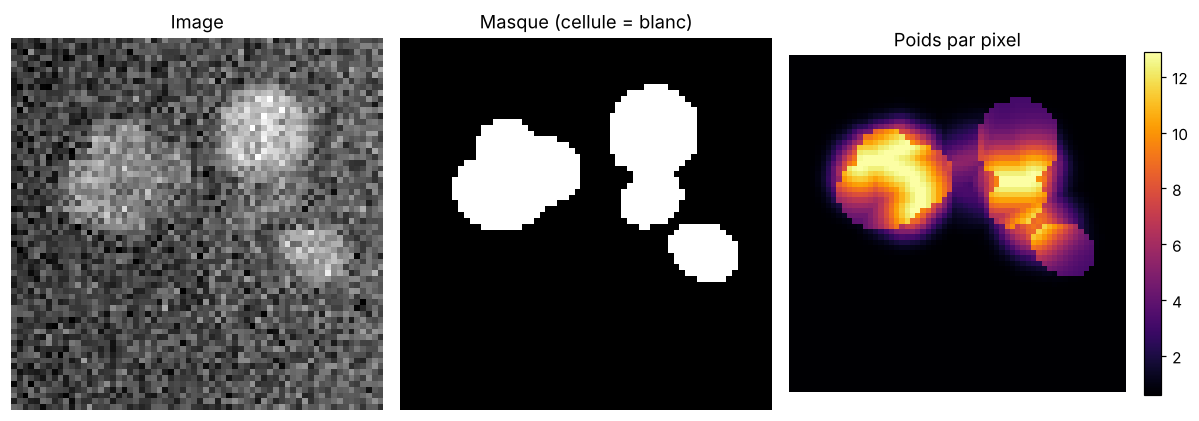

In [10]:
from scipy import ndimage

def make_sample(S=64):
    yy, xx = np.mgrid[0:S, 0:S]
    lab = np.zeros((S, S), dtype=int)
    bg = rng.uniform(0.05, 0.40) + 0.15 * xx / S
    img = bg.copy()
    for k in range(1, rng.integers(2, 7) + 1):
        cy, cx = rng.uniform(10, S - 10, 2)
        ry, rx = rng.uniform(4, 9, 2)
        ang = rng.uniform(0, np.pi)
        dy, dx = yy - cy, xx - cx
        u = dx * np.cos(ang) + dy * np.sin(ang)
        v = -dx * np.sin(ang) + dy * np.cos(ang)
        m = (u / rx) ** 2 + (v / ry) ** 2 <= 1
        lab[m & (lab == 0)] = k
        img[m] = rng.uniform(0.45, 0.90)
    img = ndimage.gaussian_filter(img, 1.0)
    img = np.clip(img + rng.normal(0, 0.12, (S, S)), 0, 1)
    return img, lab, (lab > 0).astype(int)

def make_dataset(n, S=64, w0=10.0, sigma=5.0):
    X, Y, Wt = [], [], []
    for _ in range(n):
        img, lab, fg = make_sample(S)
        ks = np.unique(lab[lab > 0])
        d = np.sort(np.stack([ndimage.distance_transform_edt(lab != k) for k in ks]), axis=0)
        d1 = d[0]
        d2 = d[1] if len(ks) > 1 else np.full((S, S), 2.0 * S)
        border = w0 * np.exp(-((d1 + d2) ** 2) / (2 * sigma ** 2))
        nfg = fg.sum(); nbg = fg.size - nfg
        wc = np.where(fg == 1, fg.size / (2 * nfg), fg.size / (2 * nbg))
        X.append(img); Y.append(fg); Wt.append(wc + border)
    return np.array(X), np.array(Y), np.array(Wt)

X, Y, Wt = make_dataset(200)
ntr, nva = 140, 30
Xtr, Ytr, Wtr = X[:ntr], Y[:ntr], Wt[:ntr]
Xva, Yva, Wva = X[ntr:ntr+nva], Y[ntr:ntr+nva], Wt[ntr:ntr+nva]
Xte, Yte = X[ntr+nva:], Y[ntr+nva:]
print(f"train / validation / test : {len(Xtr)} / {len(Xva)} / {len(Xte)}")
print(f"part de pixels « cellule » : {Y.mean():.3f}")
print(f"poids des pixels : min {Wt.min():.2f}, max {Wt.max():.2f}")

fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
ax[0].imshow(X[0], cmap="gray"); ax[0].set_title("Image")
ax[1].imshow(Y[0], cmap="gray"); ax[1].set_title("Masque (cellule = blanc)")
im = ax[2].imshow(Wt[0], cmap="inferno"); ax[2].set_title("Poids par pixel")
for a in ax: a.axis("off")
fig.colorbar(im, ax=ax[2], fraction=0.046)
plt.tight_layout()

### 8.4 Entraînement (Adam, descente de gradient par mini-lots)

Adam avec un taux d'apprentissage de 0,001. Les mini-lots font 8 images. Chaque époque, on mélange les données et on applique un retournement horizontal ou vertical au hasard. On garde les poids qui donnent la plus petite perte de validation.

In [11]:
import copy, time

def adam_step(P, G, m, v, t, lr=1e-3, b1=0.9, b2=0.999, eps=1e-8):
    for k in P:
        m[k] = b1 * m[k] + (1 - b1) * G[k]
        v[k] = b2 * v[k] + (1 - b2) * G[k] ** 2
        mh = m[k] / (1 - b1 ** t)
        vh = v[k] / (1 - b2 ** t)
        P[k] -= lr * mh / (np.sqrt(vh) + eps)

def evaluate(X_, Y_, W_, P, bs=16):
    ls, accs = [], []
    for i in range(0, len(X_), bs):
        out, _ = forward(X_[i:i+bs][..., None], P)
        l, _, _ = loss_grad(out, Y_[i:i+bs], W_[i:i+bs])
        ls.append(l); accs.append((out.argmax(-1) == Y_[i:i+bs]).mean())
    return float(np.mean(ls)), float(np.mean(accs))

def train(P, epochs=40, bs=8, lr=1e-3):
    m = {k: np.zeros_like(v) for k, v in P.items()}
    v = {k: np.zeros_like(v) for k, v in P.items()}
    t = 0
    hist = {"tr_loss": [], "va_loss": [], "tr_acc": [], "va_acc": []}
    best_loss, best_P, best_ep = np.inf, None, 0
    t0 = time.time()
    for ep in range(epochs):
        order = rng.permutation(len(Xtr))
        losses, accs = [], []
        for i in range(0, len(order), bs):
            idx = order[i:i+bs]
            x = Xtr[idx][..., None]; y = Ytr[idx]; w = Wtr[idx]
            if rng.random() < 0.5:
                x, y, w = x[:, :, ::-1], y[:, :, ::-1], w[:, :, ::-1]
            if rng.random() < 0.5:
                x, y, w = x[:, ::-1], y[:, ::-1], w[:, ::-1]
            x, y, w = np.ascontiguousarray(x), np.ascontiguousarray(y), np.ascontiguousarray(w)
            out, C = forward(x, P)
            l, dl, _ = loss_grad(out, y, w)
            G = backward(dl, P, C)
            t += 1
            adam_step(P, G, m, v, t, lr)
            losses.append(l); accs.append((out.argmax(-1) == y).mean())
        vl, va = evaluate(Xva, Yva, Wva, P)
        hist["tr_loss"].append(float(np.mean(losses))); hist["tr_acc"].append(float(np.mean(accs)))
        hist["va_loss"].append(vl); hist["va_acc"].append(va)
        if vl < best_loss:
            best_loss, best_P, best_ep = vl, copy.deepcopy(P), ep + 1
        if (ep + 1) % 5 == 0:
            print(f"époque {ep+1:>2} | perte train {np.mean(losses):.4f} | perte val {vl:.4f} | "
                  f"exactitude train {np.mean(accs):.3f} | exactitude val {va:.3f}")
    print(f"durée : {time.time() - t0:.0f} s | meilleure époque (perte val) : {best_ep}")
    return best_P, hist, best_ep

best_P, hist, best_ep = train(init_params(), epochs=40)

époque  5 | perte train 0.2699 | perte val 0.2453 | exactitude train 0.916 | exactitude val 0.928
époque 10 | perte train 0.2065 | perte val 0.1963 | exactitude train 0.940 | exactitude val 0.963
époque 15 | perte train 0.1767 | perte val 0.1735 | exactitude train 0.953 | exactitude val 0.956
époque 20 | perte train 0.1748 | perte val 0.1753 | exactitude train 0.954 | exactitude val 0.974
époque 25 | perte train 0.1486 | perte val 0.1422 | exactitude train 0.965 | exactitude val 0.973
époque 30 | perte train 0.1415 | perte val 0.1388 | exactitude train 0.966 | exactitude val 0.969
époque 35 | perte train 0.1395 | perte val 0.1293 | exactitude train 0.968 | exactitude val 0.968
époque 40 | perte train 0.1269 | perte val 0.1276 | exactitude train 0.974 | exactitude val 0.980
durée : 162 s | meilleure époque (perte val) : 40


### 8.5 Résultats sur le jeu de test

Le jeu de test (30 images)

référence seuil (appris sur train) : t = 0.60, IOU test = 0.4203
U-Net : IOU test = 0.8059

matrice de confusion (lignes = vrai, colonnes = prédit) :
            prédit fond   prédit cellule
vrai fond       109126            1587
vrai cell.        1082           11085

exactitude : 0.9783
précision  : 0.8748
rappel     : 0.9111
F1         : 0.8925
IOU        : 0.8059


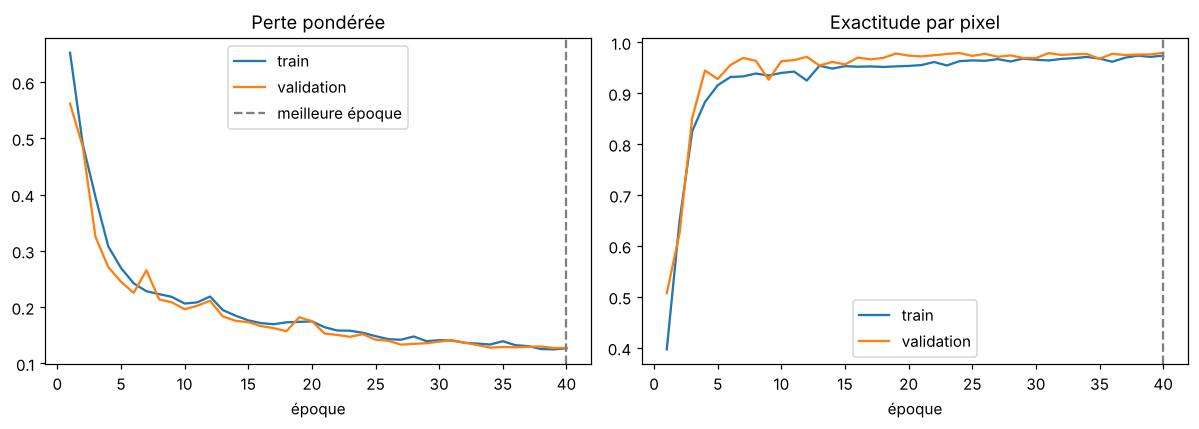

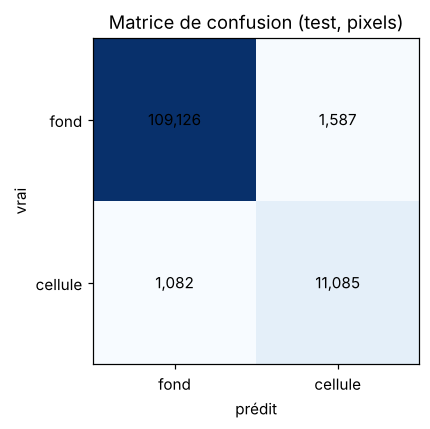

In [12]:
def predict(X_, P, bs=16):
    res = []
    for i in range(0, len(X_), bs):
        out, _ = forward(X_[i:i+bs][..., None], P)
        res.append(out.argmax(-1))
    return np.concatenate(res)

pred = predict(Xte, best_P)

# Référence simple : un seuil d'intensité choisi sur le jeu d'entraînement
def iou_of(pr, gt):
    tp = ((pr == 1) & (gt == 1)).sum(); fp = ((pr == 1) & (gt == 0)).sum(); fn = ((pr == 0) & (gt == 1)).sum()
    return tp / (tp + fp + fn)
thresholds = np.linspace(0.05, 0.95, 91)
scores = [iou_of((Xtr > t).astype(int), Ytr) for t in thresholds]
t_best = thresholds[int(np.argmax(scores))]
pred_seuil = (Xte > t_best).astype(int)
print(f"référence seuil (appris sur train) : t = {t_best:.2f}, IOU test = {iou_of(pred_seuil, Yte):.4f}")
print(f"U-Net : IOU test = {iou_of(pred, Yte):.4f}")
print()
TP = int(((pred == 1) & (Yte == 1)).sum()); TN = int(((pred == 0) & (Yte == 0)).sum())
FP = int(((pred == 1) & (Yte == 0)).sum()); FN = int(((pred == 0) & (Yte == 1)).sum())
cm = np.array([[TN, FP], [FN, TP]])
acc = (TP + TN) / cm.sum()
prec = TP / (TP + FP); rec = TP / (TP + FN)
f1 = 2 * prec * rec / (prec + rec); iou = TP / (TP + FP + FN)

print("matrice de confusion (lignes = vrai, colonnes = prédit) :")
print(f"            prédit fond   prédit cellule")
print(f"vrai fond   {TN:>10}   {FP:>13}")
print(f"vrai cell.  {FN:>10}   {TP:>13}")
print()
print(f"exactitude : {acc:.4f}")
print(f"précision  : {prec:.4f}")
print(f"rappel     : {rec:.4f}")
print(f"F1         : {f1:.4f}")
print(f"IOU        : {iou:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ep = np.arange(1, len(hist["tr_loss"]) + 1)
ax[0].plot(ep, hist["tr_loss"], label="train"); ax[0].plot(ep, hist["va_loss"], label="validation")
ax[0].axvline(best_ep, ls="--", c="grey", label="meilleure époque")
ax[0].set_title("Perte pondérée"); ax[0].set_xlabel("époque"); ax[0].legend()
ax[1].plot(ep, hist["tr_acc"], label="train"); ax[1].plot(ep, hist["va_acc"], label="validation")
ax[1].axvline(best_ep, ls="--", c="grey")
ax[1].set_title("Exactitude par pixel"); ax[1].set_xlabel("époque"); ax[1].legend()
plt.tight_layout()

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["fond", "cellule"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["fond", "cellule"])
ax.set_xlabel("prédit"); ax.set_ylabel("vrai"); ax.set_title("Matrice de confusion (test, pixels)")
plt.tight_layout()

### 8.6 Exemples de prédictions sur le jeu de test

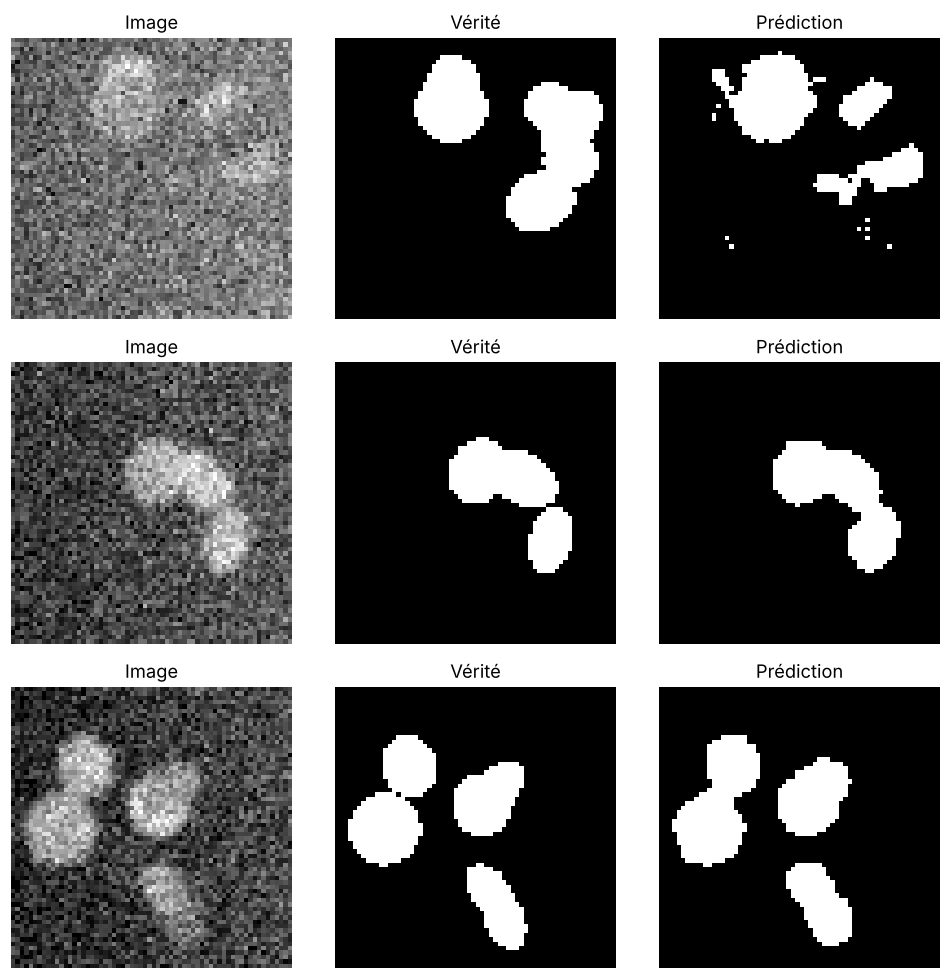

In [13]:
fig, ax = plt.subplots(3, 3, figsize=(9, 9))
for r, i in enumerate([0, 5, 12]):
    ax[r, 0].imshow(Xte[i], cmap="gray"); ax[r, 0].set_title("Image")
    ax[r, 1].imshow(Yte[i], cmap="gray"); ax[r, 1].set_title("Vérité")
    ax[r, 2].imshow(pred[i], cmap="gray"); ax[r, 2].set_title("Prédiction")
    for c in range(3): ax[r, c].axis("off")
plt.tight_layout()